# Data Center Water & Electricity Usage — PySpark

Data center electricity and water consumption (2019–2025).


In [19]:
from pyspark.sql import SparkSession
import pyspark.sql.functions as F
from pyspark.sql.window import Window

In [20]:


spark = SparkSession.builder.appName("DataCenterBasics").master("local[*]").getOrCreate()


In [21]:
df = spark.read.csv(
    "data_center_hybrid.csv",
    header=True,
    inferSchema=True,
    multiLine=True,
    escape='"',
    quote='"'
)
print("Rows:", df.count())
print("Columns:", len(df.columns))


Rows: 126770
Columns: 14


In [22]:
#from google.colab import drive
#drive.mount('/content/drive')

In [23]:
df.printSchema()

root
 |-- Year: integer (nullable = true)
 |-- Facility_ID: string (nullable = true)
 |-- Facility_Name: string (nullable = true)
 |-- Owner_Company: string (nullable = true)
 |-- City: string (nullable = true)
 |-- Country: string (nullable = true)
 |-- Facility_Type: string (nullable = true)
 |-- Estimated_Capacity_MW: double (nullable = true)
 |-- PUE: double (nullable = true)
 |-- Cooling_System_Type: string (nullable = true)
 |-- WUE_L_per_kWh: double (nullable = true)
 |-- Daily_Electricity_Usage_MWh: double (nullable = true)
 |-- Daily_Water_Usage_Gallons: double (nullable = true)
 |-- Surrounding_Water_Stress_Tier: string (nullable = true)



In [24]:
df.show(5)

+----+-----------+--------------------+-------------+------+-------+-------------------+---------------------+-----+-------------------+-------------+---------------------------+-------------------------+-----------------------------+
|Year|Facility_ID|       Facility_Name|Owner_Company|  City|Country|      Facility_Type|Estimated_Capacity_MW|  PUE|Cooling_System_Type|WUE_L_per_kWh|Daily_Electricity_Usage_MWh|Daily_Water_Usage_Gallons|Surrounding_Water_Stress_Tier|
+----+-----------+--------------------+-------------+------+-------+-------------------+---------------------+-----+-------------------+-------------+---------------------------+-------------------------+-----------------------------+
|2019|DC-D2763E00|NAP de las Americ...|    Terremark|Madrid|  Spain|Enterprise/Standard|                 6.24|1.975|        Evaporative|        1.481|                     183.62|                 36362.94|                          Low|
|2020|DC-D2763E00|NAP de las Americ...|    Terremark|Madrid|

In [25]:
df.columns

['Year',
 'Facility_ID',
 'Facility_Name',
 'Owner_Company',
 'City',
 'Country',
 'Facility_Type',
 'Estimated_Capacity_MW',
 'PUE',
 'Cooling_System_Type',
 'WUE_L_per_kWh',
 'Daily_Electricity_Usage_MWh',
 'Daily_Water_Usage_Gallons',
 'Surrounding_Water_Stress_Tier']

In [26]:
df.select("Facility_Name", "Country", 'Facility_Type',"Year", "Daily_Electricity_Usage_MWh").show(5)

+--------------------+-------+-------------------+----+---------------------------+
|       Facility_Name|Country|      Facility_Type|Year|Daily_Electricity_Usage_MWh|
+--------------------+-------+-------------------+----+---------------------------+
|NAP de las Americ...|  Spain|Enterprise/Standard|2019|                     183.62|
|NAP de las Americ...|  Spain|Enterprise/Standard|2020|                     254.34|
|NAP de las Americ...|  Spain|Enterprise/Standard|2021|                     266.85|
|NAP de las Americ...|  Spain|Enterprise/Standard|2022|                     199.14|
|NAP de las Americ...|  Spain|Enterprise/Standard|2023|                     225.94|
+--------------------+-------+-------------------+----+---------------------------+
only showing top 5 rows


In [27]:
# Only facilities in India
in_df = df.filter(df.Country == "India")
print("India rows:", in_df.count())
in_df.select("Facility_Name", "Year", "Daily_Electricity_Usage_MWh").show(5)


India rows: 2394
+-------------+----+---------------------------+
|Facility_Name|Year|Daily_Electricity_Usage_MWh|
+-------------+----+---------------------------+
|       Adayar|2019|                     236.54|
|       Adayar|2020|                     172.26|
|       Adayar|2021|                     170.22|
|       Adayar|2022|                     213.94|
|       Adayar|2023|                     249.25|
+-------------+----+---------------------------+
only showing top 5 rows


In [28]:
df.groupby('Facility_Type').count().show()

+-------------------+------+
|      Facility_Type| count|
+-------------------+------+
|      Hyperscale/AI|  9065|
|         Colocation| 12516|
|Enterprise/Standard|105189|
+-------------------+------+



In [29]:
# Only the most recent Year, and only large (Hyperscale) facilities
recent_hs = df.filter((df.Year == 2025) & (df.Facility_Type == "Hyperscale/AI"))
recent_hs.count()


1295

In [30]:
# Which facilities used the most electricity in 2025?
df.filter(df.Year == 2025) \
  .select("Facility_Name", "Country", "Daily_Electricity_Usage_MWh") \
  .orderBy(F.desc("Daily_Electricity_Usage_MWh")) \
  .show()


+--------------------+-------------+---------------------------+
|       Facility_Name|      Country|Daily_Electricity_Usage_MWh|
+--------------------+-------------+---------------------------+
|Microsoft Gaines ...|United States|                   14812.66|
|Amazon AWS IAD - ...|United States|                   14194.99|
|AWS 22 Delivery D...|    Australia|                   13573.48|
|   Microsoft - MNZ01|United States|                   13001.31|
|Southeast Asia-Si...|    Singapore|                   12938.97|
|               SYD52|    Australia|                   12869.53|
|      Quantum Campus|United States|                   12853.08|
|Amazon AWS CMH - ...|United States|                   12674.82|
|Google Loudoun Co...|United States|                   12511.09|
|Amazon AWS CMH - ...|United States|                    12422.4|
|Meta Fort Worth D...|United States|                   12413.01|
|Microsoft Goodyea...|United States|                   12404.37|
|           Indonesia|   

In [31]:
# Total electricity use per country, in the most recent Year
country_electricity = (
    df.filter(df.Year == 2025)
      .groupBy("Country")
      .agg(F.sum("Daily_Electricity_Usage_MWh").alias("total_electricity_mwh"))
      .orderBy(F.desc("total_electricity_mwh"))
)
country_electricity.show()


+--------------+---------------------+
|       Country|total_electricity_mwh|
+--------------+---------------------+
| United States|    8870315.259999992|
|United Kingdom|   355898.33999999915|
|     Australia|    304887.8200000002|
|       Germany|    289866.3899999998|
|         China|    267029.3699999998|
|   Netherlands|    242510.8600000001|
|         India|   219594.95000000004|
|        France|   214053.65000000002|
|       Ireland|   212031.82999999993|
|         Japan|            211644.74|
|        Canada|   193936.09000000017|
|        Brazil|   169385.45000000007|
|       Unknown|   166697.33999999997|
|     Singapore|   139225.58000000002|
|         Italy|   110802.63999999998|
|     Indonesia|    98277.48000000001|
|         Spain|    97223.86000000004|
|        Sweden|    97208.77999999997|
|      Malaysia|    82484.62999999999|
|     Hong Kong|    79294.48000000004|
+--------------+---------------------+
only showing top 20 rows


In [32]:
#using spark sql

In [33]:
df.createOrReplaceTempView("datacenters_wt_ec_usage")

spark.sql("""
    SELECT country, SUM(Daily_Electricity_Usage_MWh) AS total_electricity_mwh
    FROM datacenters_wt_ec_usage
    WHERE Year = 2025
    GROUP BY country
    ORDER BY total_electricity_mwh DESC
""").show()


+--------------+---------------------+
|       country|total_electricity_mwh|
+--------------+---------------------+
| United States|    8870315.259999992|
|United Kingdom|   355898.33999999915|
|     Australia|    304887.8200000002|
|       Germany|    289866.3899999998|
|         China|    267029.3699999998|
|   Netherlands|    242510.8600000001|
|         India|   219594.95000000004|
|        France|   214053.65000000002|
|       Ireland|   212031.82999999993|
|         Japan|            211644.74|
|        Canada|   193936.09000000017|
|        Brazil|   169385.45000000007|
|       Unknown|   166697.33999999997|
|     Singapore|   139225.58000000002|
|         Italy|   110802.63999999998|
|     Indonesia|    98277.48000000001|
|         Spain|    97223.86000000004|
|        Sweden|    97208.77999999997|
|      Malaysia|    82484.62999999999|
|     Hong Kong|    79294.48000000004|
+--------------+---------------------+
only showing top 20 rows


In [34]:
Yearly_electricity = (
    df.groupBy("Year")
      .agg(F.sum("Daily_Electricity_Usage_MWh").alias("total_electricity_mwh"))
      .orderBy("Year")
)
Yearly_electricity.show()


+----+---------------------+
|year|total_electricity_mwh|
+----+---------------------+
|2019|    8851682.280000003|
|2020|    9408181.489999937|
|2021|  1.002753688000009E7|
|2022| 1.0702463729999995E7|
|2023| 1.1580317840000037E7|
|2024|  1.251972176999998E7|
|2025| 1.3634135570000017E7|
+----+---------------------+



##Top countries by water usage

In [38]:
top_water_countries = (
    df.filter(df.Year == 2025)
      .groupBy("country")
      .agg(F.sum("Daily_Water_Usage_Gallons").alias("total_water_usage"))
      .orderBy(F.desc("total_water_usage")))
top_water_countries.show()


+--------------+--------------------+
|       country|   total_water_usage|
+--------------+--------------------+
| United States| 2.182892648040003E9|
|     Australia|       8.286633229E7|
|       Ireland| 6.510898770000003E7|
|         China| 5.958142117000001E7|
|United Kingdom| 5.871485052999996E7|
|         Japan| 4.689654410999999E7|
|       Germany| 4.672593657999998E7|
|   Netherlands| 4.619001881999995E7|
|         India|       4.338192201E7|
|        Brazil| 3.874349918000002E7|
|        Canada|3.8177118659999944E7|
|     Singapore|3.3630717989999995E7|
|       Unknown|2.8888351340000015E7|
|        France|2.8601727320000023E7|
|     Indonesia|2.6098370580000002E7|
|       Denmark|       2.043711808E7|
|         Italy| 1.918995797000001E7|
|        Sweden| 1.837611427999999E7|
|      Malaysia|1.6090147000000002E7|
|   Switzerland|       1.487005849E7|
+--------------+--------------------+
only showing top 20 rows


In [40]:
# Which cooling system uses the most water, on average?
water_by_cooling = (
    df.filter(df.Year == 2025)
      .groupBy("Cooling_System_Type")
      .agg(
          F.round(F.avg("Daily_Water_Usage_Gallons"), 2).alias("avg_water_gallons"),
          F.count("*").alias("facility_count"),
      )
      .orderBy(F.desc("avg_water_gallons"))
)
water_by_cooling.show()

+-------------------+-----------------+--------------+
|Cooling_System_Type|avg_water_gallons|facility_count|
+-------------------+-----------------+--------------+
|        Evaporative|        451559.64|          6516|
|      Liquid Cooled|         81731.86|           231|
|         Air Cooled|         13306.81|         11363|
+-------------------+-----------------+--------------+



In [45]:
df.select('Daily_Water_Usage_Gallons').show()

+-------------------------+
|Daily_Water_Usage_Gallons|
+-------------------------+
|                 36362.94|
|                  49833.6|
|                 53026.35|
|                  39198.3|
|                 44366.48|
|                 38435.64|
|                 44852.92|
|                  4488.46|
|                  3430.72|
|                   3679.7|
|                  2987.52|
|                  4037.37|
|                  3844.17|
|                  4284.86|
|                  2680.86|
|                  2631.04|
|                  2331.75|
|                  3318.89|
|                  2072.32|
|                  2924.89|
+-------------------------+
only showing top 20 rows


In [47]:
Yearly_water = (
    df.groupBy("Year")
      .agg(F.round(F.sum("Daily_Water_Usage_Gallons") / 1e9, 2).alias("total_water"))
      .orderBy("Year")
)
Yearly_water.show()


+----+-----------+
|Year|total_water|
+----+-----------+
|2019|        1.8|
|2020|       1.95|
|2021|       2.12|
|2022|       2.31|
|2023|       2.54|
|2024|       2.81|
|2025|       3.11|
+----+-----------+



In [62]:
# Countries with high water usage AND high electricity usage
country_usage = (
    df.filter(df.Year == 2025)
      .groupBy("Country")
      .agg(
          F.round(F.sum("Daily_Electricity_Usage_MWh"), 2).alias("total_electricity_mwh"),
          F.round(F.sum("Daily_Water_Usage_Gallons"), 2).alias("total_water_gallons"),
      )
)


w_elec = Window.orderBy(F.desc("total_electricity_mwh"))
w_water = Window.orderBy(F.desc("total_water_gallons"))

country_usage_ranked = (
    country_usage
    .withColumn("electricity_rank", F.rank().over(w_elec))
    .withColumn("water_rank", F.rank().over(w_water))
)


high_both = (
    country_usage_ranked
    .filter((F.col("electricity_rank") <= 10) & (F.col("water_rank") <= 10))
    .orderBy("electricity_rank")
)
high_both.show()

+--------------+---------------------+-------------------+----------------+----------+
|       Country|total_electricity_mwh|total_water_gallons|electricity_rank|water_rank|
+--------------+---------------------+-------------------+----------------+----------+
| United States|           8870315.26|    2.18289264804E9|               1|         1|
|United Kingdom|            355898.34|      5.871485053E7|               2|         5|
|     Australia|            304887.82|      8.286633229E7|               3|         2|
|       Germany|            289866.39|      4.672593658E7|               4|         7|
|         China|            267029.37|      5.958142117E7|               5|         4|
|   Netherlands|            242510.86|      4.619001882E7|               6|         8|
|         India|            219594.95|      4.338192201E7|               7|         9|
|       Ireland|            212031.83|       6.51089877E7|               9|         3|
|         Japan|            211644.74|     

In [49]:
import matplotlib.pyplot as plt

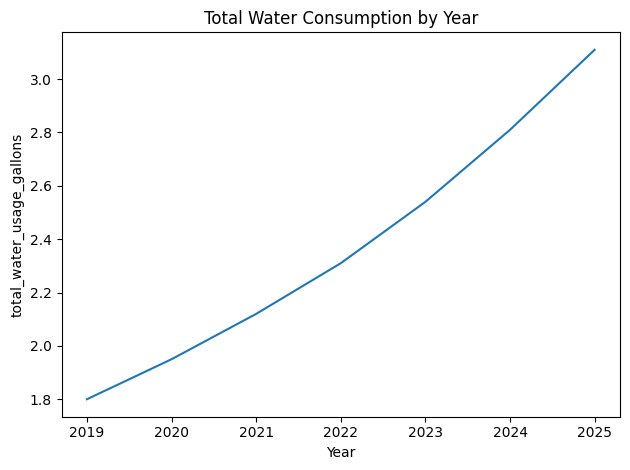

In [61]:

Yearly_water_pd = Yearly_water.toPandas()

#plt.figure(figsize=(5, 5))
plt.plot(Yearly_water_pd["Year"], Yearly_water_pd["total_water"])
plt.title("Total Water Consumption by Year")
plt.xlabel("Year")
plt.ylabel("total_water_usage_gallons")
plt.tight_layout()
plt.show()


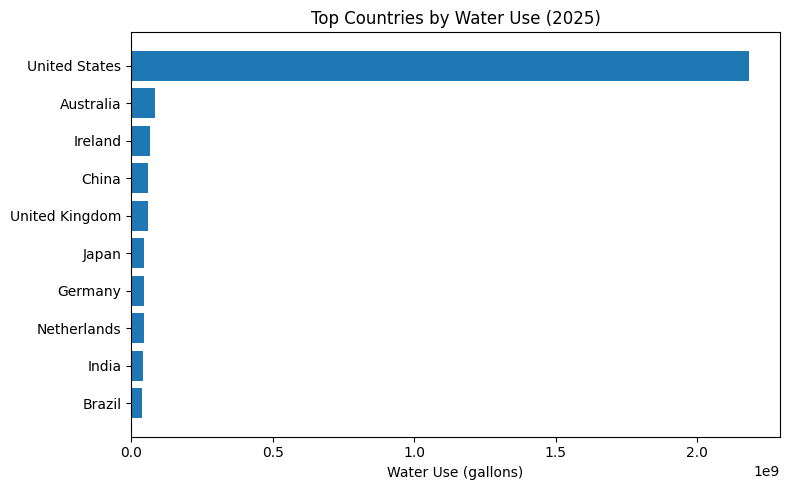

In [54]:
top_water_pd = top_water_countries.limit(10).toPandas()

plt.figure(figsize=(8, 5))
plt.barh(top_water_pd["country"][::-1], top_water_pd["total_water_usage"][::-1])
plt.xlabel("Water Use (gallons)")
plt.title("Top Countries by Water Use (2025)")
plt.tight_layout()
plt.show()


In [66]:
spark.stop()